# Lesson 8 | Deep Learning with PyTorch Workshop

This workshop introduces deep learning for image classification using PyTorch. It is based on the [ML Zoomcamp Deep Learning module (08-deep-learning)](..) but adapted to use PyTorch instead of TensorFlow/Keras.

Before preparing this workshop, I asked Gemini (inside Google Colab) to translate my Keras code into PyTorch and [this is what happened](https://colab.research.google.com/drive/1_kvvbi_msBuTFkkdLxMEpB3mj-Jhh-Bc?usp=sharing). This workshop is based on the code from this notebook.

---

## Workshop Overview

In this workshop, you will learn how to build an image classification model using PyTorch and transfer learning. We'll work with a clothing dataset and progressively improve our model through experimentation and optimization.


<div style="display: flex; gap: 60px;">

<div style="flex: 1;">

## Plan

- Introduction to PyTorch for deep learning
- Loading and preprocessing image data
- Using pre-trained models (MobileNetV2)
- Understanding convolutional neural networks (CNNs)
- Transfer learning: adapting pre-trained models
- Hyperparameter tuning: learning rate optimization
- Model checkpointing: saving the best model
- Adding more layers to improve performance
- Dropout regularization to prevent overfitting
- Data augmentation for better generalization
- Training the final model
- Using the model for predictions
- Exporting models to ONNX format

</div>

<div style="flex: 1;">

## Prerequisites

Tools:

- PyTorch
- torchvision
- PIL (Pillow)
- NumPy

</div>

</div>


## Setup

We will use Google Colab, so no setup (like installing libraries or CUDA) is required.

Download the dataset:

In [1]:
!git clone https://github.com/alexeygrigorev/clothing-dataset-small.git ./data/clothing-dataset-small

Cloning into './data/clothing-dataset-small'...
remote: Enumerating objects: 3839, done.
remote: Counting objects: 100% (400/400), done.
remote: Compressing objects: 100% (400/400), done.
remote: Total 3839 (delta 9), reused 385 (delta 0), pack-reused 3439 (from 1)
Receiving objects: 100% (3839/3839), 100.58 MiB | 24.14 MiB/s, done.
Resolving deltas: 100% (10/10), done.


## 1. Introduction to PyTorch

PyTorch is a popular open-source deep learning framework developed by Facebook's AI Research lab. It provides:
- Dynamic computation graphs (define-by-run)
- Pythonic API
- Strong GPU acceleration
- Rich ecosystem of tools and libraries

Key Differences from TensorFlow/Keras:

| TensorFlow/Keras | PyTorch |
|------------------|---------|
| `model.fit()` | Manual training loop |
| `ImageDataGenerator` | `Dataset` + `DataLoader` + `transforms` |
| `keras.layers.Dense()` | `nn.Linear()` |
| `keras.Model` | `nn.Module` |
| `.h5` or `.keras` files | `.pth` or `.pt` files |

## 2. PyTorch and Image Loading

PyTorch is a popular open-source deep learning framework developed by Facebook's AI Research lab.

Key differences from TensorFlow/Keras:
- Dynamic computation graphs (define-by-run)
- More Pythonic and flexible
- Manual training loops instead of `model.fit()`
- Explicit device management (CPU/GPU)

### Loading and Preprocessing Images

Images are represented as 3D arrays:
- Height × Width × Channels
- Channels: RGB (Red, Green, Blue)
- Each channel: 8 bits (0-255 values)

In [9]:
from PIL import Image
import numpy as np

In [5]:
# Load an image
img = Image.open('./data/clothing-dataset-small/train/pants/0098b991-e36e-4ef1-b5ee-4154b21e2a92.jpg')


In [7]:
# Resize to target size
img = img.resize((224, 224))

In [10]:
# Convert to numpy array
x = np.array(img)
print(x.shape)  # (224, 224, 3)

(224, 224, 3)


array([[[179, 181, 176],
        [179, 181, 176],
        [179, 181, 176],
        ...,
        [237, 230, 222],
        [238, 231, 223],
        [236, 229, 221]],

       [[180, 181, 176],
        [177, 178, 173],
        [177, 178, 173],
        ...,
        [237, 230, 222],
        [237, 230, 222],
        [235, 228, 220]],

       [[178, 179, 174],
        [175, 176, 171],
        [175, 176, 171],
        ...,
        [237, 230, 222],
        [237, 230, 222],
        [234, 227, 219]],

       ...,

       [[155, 149, 137],
        [155, 149, 137],
        [158, 152, 140],
        ...,
        [157, 149, 138],
        [159, 151, 140],
        [156, 148, 137]],

       [[151, 145, 133],
        [152, 146, 134],
        [157, 151, 139],
        ...,
        [155, 147, 136],
        [157, 149, 138],
        [155, 147, 136]],

       [[150, 144, 132],
        [152, 146, 134],
        [157, 151, 139],
        ...,
        [154, 146, 135],
        [155, 147, 136],
        [153, 145, 134]]], shape=(224, 224, 3), dtype=uint8)
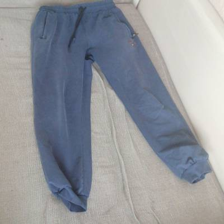

In [11]:
np.array(img)

## 3. Pre-trained Models

Instead of training from scratch, we'll use a model pre-trained on ImageNet (1.4M images, 1000 classes).

Why use pre-trained models?

- Already learned to recognize edges, textures, shapes
- Saves training time
- Works well even with small datasets
- Better performance than training from scratch

### Using MobileNetV2

We'll use MobileNetV2 (in the original tutorial we used Xception):

In [12]:
import torch
import torchvision.models as models
from torchvision import transforms
import numpy as np

In [13]:
# Load pre-trained model
model = models.mobilenet_v2(weights='IMAGENET1K_V1')
model.eval()

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 122MB/s]


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [14]:
# Preprocessing for MobileNetV2
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

Now do the prediction:

In [16]:
img = Image.open('./data/clothing-dataset-small/train/pants/0098b991-e36e-4ef1-b5ee-4154b21e2a92.jpg')
img_t = preprocess(img)
batch_t = torch.unsqueeze(img_t, 0)

In [18]:
# Make prediction
with torch.no_grad():
    output = model(batch_t)

In [19]:
output.shape

torch.Size([1, 1000])

In [20]:
# Get top predictions
_, indices = torch.sort(output, descending=True)

In [21]:
indices

tensor([[608, 834, 474, 841, 689, 824, 501, 885, 906, 869, 601, 911, 775, 735,
         457, 655, 697, 578, 610, 434, 797, 411, 399, 452, 842, 568, 431, 617,
         516, 678, 591, 414, 796, 570, 840, 523, 793, 630, 636, 894, 903, 464,
         638, 502, 658, 614, 465, 588, 830, 515, 589, 691, 749, 808, 435, 529,
         780, 606, 806, 728, 837, 672, 887, 459, 643, 615, 702, 552, 480, 514,
         597, 777, 774, 512, 600, 823, 731, 490, 680, 790, 473, 419, 794, 715,
         772, 389, 602, 914, 451, 233, 667, 223, 652, 639, 750, 836, 831, 400,
         520, 676, 897, 876, 237, 770, 669, 585, 838, 748, 977, 177, 153, 559,
         395, 443, 487, 416, 461, 785, 982, 258, 172, 882, 257, 872, 456, 477,
         999, 801, 587, 169, 183, 171, 713, 499, 195, 741, 358, 584, 182, 463,
         250, 151, 700, 558, 170,  34, 447, 936, 557, 679, 224, 433, 543, 259,
         178, 222, 771, 879, 445, 513, 683, 627, 753, 843, 462, 765, 202, 197,
         173, 861, 265, 246, 792, 192, 811, 646, 256

Let's see what's inside:

In [22]:
!wget https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt -O ./data/imagenet_classes.txt

--2026-11-22 03:06:15--  https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10472 (10K) [text/plain]
Saving to: ‘./data/imagenet_classes.txt’

./data/imagenet_cla 100%[===================>]  10.23K  --.-KB/s    in 0s      

2026-11-22 03:06:15 (20.6 MB/s) - ‘./data/imagenet_classes.txt’ saved [10472/10472]



In [24]:
# Load ImageNet class names
with open("./data/imagenet_classes.txt", "r") as f:
    categories = [s.strip() for s in f.readlines()]

In [25]:
# Get top 5 predictions
top5_indices = indices[0, :5].tolist()
top5_classes = [categories[i] for i in top5_indices]

print("Top 5 predictions:")
for i, class_name in enumerate(top5_classes):
    print(f"{i+1}: {class_name}")

Top 5 predictions:
1: jean
2: suit
3: cardigan
4: sweatshirt
5: overskirt


Key concepts:
- Input size: MobileNetV2 expects 224×224 images (Xception uses 299×299)
- Normalization: Images scaled with ImageNet mean and std
- Batch size: Number of images processed together
- Batch dimension: Shape (batch_size, channels, height, width) - e.g., (1, 3, 224, 224)



## 4. Convolutional Neural Networks

Convolutional Neural Networks (CNNs) are specialized neural networks for processing grid-like data such as images.

Key Components:

1. Convolutional Layer: Extracts features using filters
   - Applies filters (e.g., 3×3, 5×5) to detect patterns
   - Creates feature maps (one per filter)
   - Detects edges, textures, shapes

2. ReLU Activation: Introduces non-linearity
   - `f(x) = max(0, x)`
   - Sets negative values to 0
   - Helps network learn complex patterns

3. Pooling Layer: Down-samples feature maps
   - Reduces spatial dimensions
   - Max pooling: takes maximum value in a region
   - Makes features more robust to small translations

4. Fully Connected (Dense) Layer: Final classification
   - Flattens 2D feature maps to 1D vector
   - Connects to output classes

CNN Workflow:
```
Input Image → Conv + ReLU → Pooling → Conv + ReLU → Pooling → Flatten → Dense → Output
```

## 5. Transfer Learning

Transfer Learning reuses a model trained on one task (ImageNet) for a different task (clothing classification).

Approach:

1. Load pre-trained model (feature extractor)
2. Remove original classification head
3. Freeze convolutional layers
4. Add custom layers for our task
5. Train only the new layers

### Custom Dataset Class

First, create a PyTorch `Dataset` to load images:

In [26]:
import os
from torch.utils.data import Dataset
from PIL import Image

class ClothingDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []
        self.classes = sorted(os.listdir(data_dir))
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}

        for label_name in self.classes:
            label_dir = os.path.join(data_dir, label_name)
            for img_name in os.listdir(label_dir):
                self.image_paths.append(os.path.join(label_dir, img_name))
                self.labels.append(self.class_to_idx[label_name])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

### Simple Preprocessing


In [27]:
from torchvision import transforms

input_size = 224

# ImageNet normalization values
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Simple transforms - just resize and normalize
train_transforms = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

val_transforms = transforms.Compose([
    transforms.Resize((input_size, input_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

### Create DataLoaders


In [28]:
from torch.utils.data import DataLoader

train_dataset = ClothingDataset(
    data_dir='./data/clothing-dataset-small/train',
    transform=train_transforms
)

val_dataset = ClothingDataset(
    data_dir='./data/clothing-dataset-small/validation',
    transform=val_transforms
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

### Build the Model

In [30]:
import torch.nn as nn

In [31]:
class ClothingClassifierMobileNet(nn.Module):
    def __init__(self, num_classes=10):
        super(ClothingClassifierMobileNet, self).__init__()

        # Load pre-trained MobileNetV2
        self.base_model = models.mobilenet_v2(weights='IMAGENET1K_V1')

        # Freeze base model parameters
        for param in self.base_model.parameters():
            param.requires_grad = False

        # Remove original classifier
        self.base_model.classifier = nn.Identity()

        # Add custom layers
        self.global_avg_pooling = nn.AdaptiveAvgPool2d((1, 1))
        self.output_layer = nn.Linear(1280, num_classes)

    def forward(self, x):
        x = self.base_model.features(x)
        x = self.global_avg_pooling(x)
        x = torch.flatten(x, 1)
        x = self.output_layer(x)
        return x

### Train the Model

In [32]:
import torch.optim as optim

In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ClothingClassifierMobileNet(num_classes=10)
model.to(device)

optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

In [34]:
model.forward(torch.rand(1,3,224,244).to(device)) # example prediction (any)

tensor([[ 0.1054,  0.6614,  0.2160, -0.5619,  0.2235, -0.1735,  0.1036,  0.0038,
         -0.0258, -0.0390]], device='cuda:0', grad_fn=<AddmmBackward0>)

now train it:

In [35]:
# Training loop
num_epochs = 10

for epoch in range(num_epochs):
    # Training phase
    model.train()  # Set the model to training mode
    running_loss = 0.0
    correct = 0
    total = 0

    # Iterate over the training data
    for inputs, labels in train_loader:
        # Move data to the specified device (GPU or CPU)
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients to prevent accumulation
        optimizer.zero_grad()
        # Forward pass
        outputs = model(inputs)
        # Calculate the loss
        loss = criterion(outputs, labels)
        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate training loss
        running_loss += loss.item()
        # Get predictions
        _, predicted = torch.max(outputs.data, 1)
        # Update total and correct predictions
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    # Calculate average training loss and accuracy
    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    # Validation phase
    model.eval()  # Set the model to evaluation mode
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    # Disable gradient calculation for validation
    with torch.no_grad():
        # Iterate over the validation data
        for inputs, labels in val_loader:
            # Move data to the specified device (GPU or CPU)
            inputs, labels = inputs.to(device), labels.to(device)
            # Forward pass
            outputs = model(inputs)
            # Calculate the loss
            loss = criterion(outputs, labels)

            # Accumulate validation loss
            val_loss += loss.item()
            # Get predictions
            _, predicted = torch.max(outputs.data, 1)
            # Update total and correct predictions
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    # Calculate average validation loss and accuracy
    val_loss /= len(val_loader)
    val_acc = val_correct / val_total

    # Print epoch results
    print(f'Epoch {epoch+1}/{num_epochs}')
    print(f'  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}')
    print(f'  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

Epoch 1/10
  Train Loss: 1.5146, Train Acc: 0.6229
  Val Loss: 0.9540, Val Acc: 0.7126
Epoch 2/10
  Train Loss: 0.7812, Train Acc: 0.7510
  Val Loss: 1.2101, Val Acc: 0.6716
Epoch 3/10
  Train Loss: 0.6993, Train Acc: 0.7956
  Val Loss: 0.9156, Val Acc: 0.7683
Epoch 4/10
  Train Loss: 0.5625, Train Acc: 0.8318
  Val Loss: 1.1839, Val Acc: 0.7243
Epoch 5/10
  Train Loss: 0.6063, Train Acc: 0.8263
  Val Loss: 0.9229, Val Acc: 0.7830
Epoch 6/10
  Train Loss: 0.5713, Train Acc: 0.8360
  Val Loss: 0.9560, Val Acc: 0.7830
Epoch 7/10
  Train Loss: 0.5818, Train Acc: 0.8416
  Val Loss: 1.1976, Val Acc: 0.7507
Epoch 8/10
  Train Loss: 0.4713, Train Acc: 0.8595
  Val Loss: 0.8995, Val Acc: 0.7713
Epoch 9/10
  Train Loss: 0.4309, Train Acc: 0.8667
  Val Loss: 0.9874, Val Acc: 0.7625
Epoch 10/10
  Train Loss: 0.4875, Train Acc: 0.8546
  Val Loss: 1.1344, Val Acc: 0.7507


It's a lower-level framework, that's why we need to implement some of these things like calculating accuracy on validation.

The line `optimizer.zero_grad()` is crucial in the training loop.

In PyTorch, gradients are accumulated by default. This means that if you don't zero the gradients before calculating the gradients for the current batch, the gradients from the previous batch will be added to the gradients of the current batch. This would lead to incorrect updates to your model's parameters.

By calling `optimizer.zero_grad()`, you clear out the old gradients, ensuring that the gradients calculated during the `loss.backward()` call are only based on the current batch of data. This is essential for the optimizer to take the correct step during `optimizer.step()`.

`model.train()` and `model.eval()` are needed to manage the behavior of certain layers during training and evaluation.

`model.train()` sets the model to training mode. In training mode, layers like Dropout and BatchNorm behave differently. Dropout layers are active (randomly dropping neurons), and BatchNorm layers update their running statistics (mean and variance) based on the current batch.

`model.eval()` sets the model to evaluation mode. In evaluation mode, Dropout layers are inactive (they pass through all neurons), and BatchNorm layers use their accumulated running statistics instead of the current batch statistics. This ensures consistent behavior during inference and prevents randomness from affecting the evaluation results.


Let's put it inside a function so it's easier for us to call it:


In [36]:
def train_and_evaluate(model, optimizer, train_loader, val_loader, criterion, num_epochs, device):
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = correct / total

        # Validation phase
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss /= len(val_loader)
        val_acc = val_correct / val_total

        print(f'Epoch {epoch+1}/{num_epochs}')
        print(f'  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}')
        print(f'  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

## 6. Tuning the Learning Rate

The learning rate controls how much to update model weights during training. It's one of the most important hyperparameters.

Analogy: Reading speed
- Too fast: Skip details, poor understanding (may not converge)
- Too slow: Never finish the book (training takes too long)
- Just right: Good comprehension and efficiency

Experimentation approach:

1. Try multiple values: `[0.0001, 0.001, 0.01, 0.1]`
2. Train for a few epochs each
3. Compare validation accuracy
4. Choose the rate with best performance and smallest train/val gap

In [37]:
def make_model(learning_rate=0.01):
    model = ClothingClassifierMobileNet(num_classes=10)
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    return model, optimizer

Let's test different learning rates:

In [38]:
learning_rates = [0.0001, 0.001, 0.01, 0.1]

for lr in learning_rates:
    print(f'\n=== Learning Rate: {lr} ===')
    model, optimizer = make_model(learning_rate=lr)
    train_and_evaluate(model, optimizer, train_loader, val_loader, criterion, num_epochs, device)


=== Learning Rate: 0.0001 ===
Epoch 1/10
  Train Loss: 1.9681, Train Acc: 0.3357
  Val Loss: 1.7328, Val Acc: 0.4282
Epoch 2/10
  Train Loss: 1.6129, Train Acc: 0.4892
  Val Loss: 1.4553, Val Acc: 0.5191
Epoch 3/10
  Train Loss: 1.3877, Train Acc: 0.5821
  Val Loss: 1.2658, Val Acc: 0.5982
Epoch 4/10
  Train Loss: 1.2342, Train Acc: 0.6317
  Val Loss: 1.1436, Val Acc: 0.6540
Epoch 5/10
  Train Loss: 1.1164, Train Acc: 0.6799
  Val Loss: 1.0510, Val Acc: 0.7126
Epoch 6/10
  Train Loss: 1.0382, Train Acc: 0.7096
  Val Loss: 0.9748, Val Acc: 0.7390
Epoch 7/10
  Train Loss: 0.9672, Train Acc: 0.7337
  Val Loss: 0.9090, Val Acc: 0.7419
Epoch 8/10
  Train Loss: 0.9100, Train Acc: 0.7480
  Val Loss: 0.8732, Val Acc: 0.7419
Epoch 9/10
  Train Loss: 0.8670, Train Acc: 0.7608
  Val Loss: 0.8288, Val Acc: 0.7654
Epoch 10/10
  Train Loss: 0.8179, Train Acc: 0.7764
  Val Loss: 0.8015, Val Acc: 0.7742

=== Learning Rate: 0.001 ===
Epoch 1/10
  Train Loss: 1.3214, Train Acc: 0.5828
  Val Loss: 0.845

## 7. Model Checkpointing

Checkpointing saves the model during training to:
- Keep the best performing model
- Resume training if interrupted
- Avoid losing progress

Update the train function:


In [55]:
def train_and_evaluate(model, optimizer, train_loader, val_loader, criterion, num_epochs, device, name='mobilenet_v2'):
    os.makedirs('./models', exist_ok=True)

    best_val_accuracy = 0.0
    history = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}

    for epoch in range(num_epochs):
        # Training phase
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            predicted = outputs.argmax(1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = correct / total

        # Validation phase
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                predicted = outputs.argmax(1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss /= len(val_loader)
        val_acc = val_correct / val_total

        # Save history
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        print(f'Epoch {epoch+1}/{num_epochs}')
        print(f'  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}')
        print(f'  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

        # Checkpoint the model if validation accuracy improved
        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            checkpoint_path = f'./models/{name}_{epoch+1:02d}_{val_acc:.3f}.pth'
            torch.save(model.state_dict(), checkpoint_path)
            print(f'Checkpoint saved: {checkpoint_path}')

    return history

TensorFlow/Keras equivalent:
- Keras: `ModelCheckpoint` callback
- PyTorch: Manual saving in training loop

## 8. Adding Inner Layers

We can add intermediate dense layers between feature extraction and output:

In [51]:
class ClothingClassifierMobileNet(nn.Module):
    def __init__(self, size_inner=100, num_classes=10):
        super(ClothingClassifierMobileNet, self).__init__()

        self.base_model = models.mobilenet_v2(weights='IMAGENET1K_V1')

        for param in self.base_model.parameters():
            param.requires_grad = False

        self.base_model.classifier = nn.Identity()

        self.global_avg_pooling = nn.AdaptiveAvgPool2d((1, 1))
        self.inner = nn.Linear(1280, size_inner)  # New inner layer
        self.relu = nn.ReLU()
        self.output_layer = nn.Linear(size_inner, num_classes)

    def forward(self, x):
        x = self.base_model.features(x)
        x = self.global_avg_pooling(x)
        x = torch.flatten(x, 1)
        x = self.inner(x)
        x = self.relu(x)
        x = self.output_layer(x)
        return x

Update `make_model`:

In [52]:
def make_model(learning_rate=0.001, size_inner=100):
    model = ClothingClassifierMobileNet(
        num_classes=10,
        size_inner=size_inner
    )
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    return model, optimizer

Experiment with different sizes:
- Try: `size_inner = [10, 100, 1000]`
- Larger layers: more capacity, may overfit
- Smaller layers: faster, may underfit

Key points:
- Inner layer uses ReLU activation
- Output layer has no activation (logits)
- `CrossEntropyLoss` applies softmax internally

In [53]:
for size_inner in [10, 100, 500, 1000]:
  print(f'\n=== Size Inner: {size_inner} ===')
  model, optimizer = make_model(
      learning_rate=0.001,
      size_inner=size_inner
  )
  train_and_evaluate(
        model, optimizer, train_loader, val_loader, criterion, num_epochs,
        device,
  )


=== Size Inner: 10 ===
Epoch 1/10
  Train Loss: 1.8000, Train Acc: 0.4113
  Val Loss: 1.5119, Val Acc: 0.4751
Checkpoint saved: ./models/mobilenet_v2_01_0.475.pth
Epoch 2/10
  Train Loss: 1.3365, Train Acc: 0.5763
  Val Loss: 1.2310, Val Acc: 0.5455
Checkpoint saved: ./models/mobilenet_v2_02_0.545.pth
Epoch 3/10
  Train Loss: 1.1081, Train Acc: 0.6372
  Val Loss: 1.0584, Val Acc: 0.6188
Checkpoint saved: ./models/mobilenet_v2_03_0.619.pth
Epoch 4/10
  Train Loss: 0.9842, Train Acc: 0.6669
  Val Loss: 0.9502, Val Acc: 0.6334
Checkpoint saved: ./models/mobilenet_v2_04_0.633.pth
Epoch 5/10
  Train Loss: 0.8968, Train Acc: 0.6982
  Val Loss: 0.9030, Val Acc: 0.6657
Checkpoint saved: ./models/mobilenet_v2_05_0.666.pth
Epoch 6/10
  Train Loss: 0.8114, Train Acc: 0.7259
  Val Loss: 0.8275, Val Acc: 0.7009
Checkpoint saved: ./models/mobilenet_v2_06_0.701.pth
Epoch 7/10
  Train Loss: 0.7793, Train Acc: 0.7373
  Val Loss: 0.7966, Val Acc: 0.7038
Checkpoint saved: ./models/mobilenet_v2_07_0.704.

## 9. Dropout Regularization

Dropout randomly drops neurons during training to prevent overfitting.

How it works:
- Training: randomly set fraction of activations to 0
- Inference: use all neurons (dropout disabled automatically)
- Creates ensemble effect

Benefits:
- Prevents relying on specific features
- Forces learning robust patterns
- Reduces overfitting


In [56]:
class ClothingClassifierMobileNet(nn.Module):
    def __init__(self, size_inner=100, droprate=0.2, num_classes=10):
        super(ClothingClassifierMobileNet, self).__init__()

        self.base_model = models.mobilenet_v2(weights='IMAGENET1K_V1')

        for param in self.base_model.parameters():
            param.requires_grad = False

        self.base_model.classifier = nn.Identity()

        self.global_avg_pooling = nn.AdaptiveAvgPool2d((1, 1))
        self.inner = nn.Linear(1280, size_inner)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(droprate)  # Add dropout
        self.output_layer = nn.Linear(size_inner, num_classes)

    def forward(self, x):
        x = self.base_model.features(x)
        x = self.global_avg_pooling(x)
        x = torch.flatten(x, 1)
        x = self.inner(x)
        x = self.relu(x)
        x = self.dropout(x)  # Apply dropout
        x = self.output_layer(x)
        return x

Update our function:

In [57]:
def make_model(
        learning_rate=0.001,
        size_inner=100,
        droprate=0.2
):
    model = ClothingClassifierMobileNet(
        num_classes=10,
        size_inner=size_inner,
        droprate=droprate
    )
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    return model, optimizer

Experimentation:
- Try: `droprate = [0.0, 0.2, 0.5, 0.8]`
- Typical values: 0.2 to 0.5
- Higher dropout may need more training epochs


In [58]:
size_inner = 100   # use the best size_inner from your previous experiment
num_epochs = 50
histories = {}

for droprate in [0.1, 0.2, 0.5, 0.7, 0.8]:
    print(f'\n=== Drop rate: {droprate} ===')
    model, optimizer = make_model(
        learning_rate=0.001,
        size_inner=size_inner,
        droprate=droprate
    )
    histories[droprate] = train_and_evaluate(
        model, optimizer, train_loader, val_loader, criterion, num_epochs, device,
        name=f'mobilenet_v3_inner{size_inner}_drop{droprate}'
    )


=== Drop rate: 0.1 ===
Epoch 1/50
  Train Loss: 1.3370, Train Acc: 0.5642
  Val Loss: 0.8477, Val Acc: 0.6833
Checkpoint saved: ./models/mobilenet_v3_inner100_drop0.1_01_0.683.pth
Epoch 2/50
  Train Loss: 0.7562, Train Acc: 0.7520
  Val Loss: 0.6283, Val Acc: 0.7713
Checkpoint saved: ./models/mobilenet_v3_inner100_drop0.1_02_0.771.pth
Epoch 3/50
  Train Loss: 0.6339, Train Acc: 0.7885
  Val Loss: 0.5699, Val Acc: 0.7977
Checkpoint saved: ./models/mobilenet_v3_inner100_drop0.1_03_0.798.pth
Epoch 4/50
  Train Loss: 0.5625, Train Acc: 0.8080
  Val Loss: 0.5908, Val Acc: 0.7625
Epoch 5/50
  Train Loss: 0.4968, Train Acc: 0.8282
  Val Loss: 0.5432, Val Acc: 0.8035
Checkpoint saved: ./models/mobilenet_v3_inner100_drop0.1_05_0.804.pth
Epoch 6/50
  Train Loss: 0.4864, Train Acc: 0.8328
  Val Loss: 0.6103, Val Acc: 0.7683
Epoch 7/50
  Train Loss: 0.4390, Train Acc: 0.8497
  Val Loss: 0.5932, Val Acc: 0.7801
Epoch 8/50
  Train Loss: 0.4247, Train Acc: 0.8527
  Val Loss: 0.5756, Val Acc: 0.7977


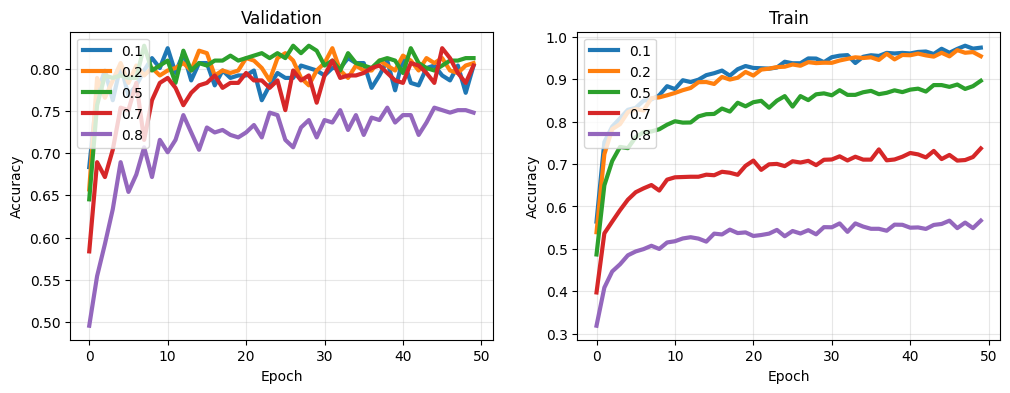

In [60]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for droprate, h in histories.items():
    ax1.plot(h['val_acc'], label=droprate, linewidth=3)
    ax2.plot(h['train_acc'], label=droprate, linewidth=3)

ax1.set_title('Validation')
ax2.set_title('Train')
for ax in (ax1, ax2):
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)

plt.show()

In [61]:
import os
import re

files = [f for f in os.listdir('./models')
         if f.startswith('mobilenet_v3_') and '_drop' in f and f.endswith('.pth')]

pattern = r'inner(\d+)_drop([\d.]+)_(\d+)_([\d.]+)\.pth'

results = []
for f in files:
    size_inner, droprate, epoch, val_acc = re.search(pattern, f).groups()
    results.append((float(val_acc), int(size_inner), float(droprate), int(epoch), f))

results.sort(reverse=True)
for r in results[:5]:
    print(r)

best_acc, best_inner, best_drop, best_epoch, best_file = results[0]
print(f'\nBest: {best_file}')

(0.827, 100, 0.5, 8, 'mobilenet_v3_inner100_drop0.5_08_0.827.pth')
(0.824, 100, 0.7, 46, 'mobilenet_v3_inner100_drop0.7_46_0.824.pth')
(0.824, 100, 0.2, 32, 'mobilenet_v3_inner100_drop0.2_32_0.824.pth')
(0.824, 100, 0.1, 11, 'mobilenet_v3_inner100_drop0.1_11_0.824.pth')
(0.821, 100, 0.2, 15, 'mobilenet_v3_inner100_drop0.2_15_0.821.pth')

Best: mobilenet_v3_inner100_drop0.5_08_0.827.pth


## 10. Data Augmentation

Data Augmentation artificially increases dataset size by applying random transformations to training images.

Common transformations:
- Rotation
- Horizontal/vertical flipping
- Zooming (random cropping)
- Shifting
- Shearing

These transformations create varied training views while preserving the
underlying class label:

![Training-time augmentation creates rotated, cropped, and flipped views of the same pants image while keeping the pants label.](./images/training-time-augmentation-imagegen.jpg)

Important rules:
- ✅ Apply ONLY to training data
- ❌ Never augment validation/test data

In [59]:
input_size = 224

# ImageNet normalization values
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transforms WITH augmentation
train_transforms = transforms.Compose([
    transforms.RandomRotation(10),           # Rotate up to 10 degrees
    transforms.RandomResizedCrop(224, scale=(0.9, 1.0)),  # Zoom
    transforms.RandomHorizontalFlip(),       # Horizontal flip
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Validation transforms - NO augmentation, same as before
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

When to use augmentation:
1. Small datasets
2. Risk of overfitting
3. Images can appear in different orientations

Tips:
- Choose augmentations that make sense for your data
- Too much augmentation can hurt performance
- Usually requires longer training (more epochs)
- If no improvement after ~20 epochs, don't use it

In [62]:
num_epochs = 50
size_inner = 100   # use the best size_inner from your previous experiment
droprate = 0.5     # using the best from previus experiment
learning_rate=0.001


print(f'\n=== Augmentation, inner={size_inner}, drop={droprate} ===')
model, optimizer = make_model(
    learning_rate=learning_rate,
    size_inner=size_inner,
    droprate=droprate
)
history_final = train_and_evaluate(
    model, optimizer, train_loader, val_loader, criterion, num_epochs, device,
    name=f'mobilenet_v4_w_augmentation_inner{size_inner}_drop{droprate}'
)


=== Augmentation, inner=100, drop=0.5 ===
Epoch 1/50
  Train Loss: 1.5777, Train Acc: 0.4772
  Val Loss: 1.1032, Val Acc: 0.6833
Checkpoint saved: ./models/mobilenet_v4_w_augmentation_inner100_drop0.5_01_0.683.pth
Epoch 2/50
  Train Loss: 1.0582, Train Acc: 0.6509
  Val Loss: 0.8009, Val Acc: 0.7067
Checkpoint saved: ./models/mobilenet_v4_w_augmentation_inner100_drop0.5_02_0.707.pth
Epoch 3/50
  Train Loss: 0.8847, Train Acc: 0.6952
  Val Loss: 0.6984, Val Acc: 0.7449
Checkpoint saved: ./models/mobilenet_v4_w_augmentation_inner100_drop0.5_03_0.745.pth
Epoch 4/50
  Train Loss: 0.8014, Train Acc: 0.7259
  Val Loss: 0.6502, Val Acc: 0.7977
Checkpoint saved: ./models/mobilenet_v4_w_augmentation_inner100_drop0.5_04_0.798.pth
Epoch 5/50
  Train Loss: 0.7284, Train Acc: 0.7510
  Val Loss: 0.6056, Val Acc: 0.7947
Epoch 6/50
  Train Loss: 0.6838, Train Acc: 0.7624
  Val Loss: 0.5921, Val Acc: 0.7859
Epoch 7/50
  Train Loss: 0.6637, Train Acc: 0.7806
  Val Loss: 0.5553, Val Acc: 0.8152
Checkpoi

In [63]:
import os
import re

prefix = 'mobilenet_v4_w_augmentation_'
files = [f for f in os.listdir('./models') if f.startswith(prefix) and f.endswith('.pth')]

pattern = r'inner(\d+)_drop([\d.]+)_(\d+)_([\d.]+)\.pth'

results = []
for f in files:
    size_inner, droprate, epoch, val_acc = re.search(pattern, f).groups()
    results.append((float(val_acc), int(size_inner), float(droprate), int(epoch), f))

results.sort(reverse=True)
for r in results[:5]:
    print(r)

best_acc, best_inner, best_drop, best_epoch, best_file = results[0]
print(f'\nBest: {best_file}')


(0.836, 100, 0.5, 14, 'mobilenet_v4_w_augmentation_inner100_drop0.5_14_0.836.pth')
(0.824, 100, 0.5, 8, 'mobilenet_v4_w_augmentation_inner100_drop0.5_08_0.824.pth')
(0.815, 100, 0.5, 7, 'mobilenet_v4_w_augmentation_inner100_drop0.5_07_0.815.pth')
(0.798, 100, 0.5, 4, 'mobilenet_v4_w_augmentation_inner100_drop0.5_04_0.798.pth')
(0.745, 100, 0.5, 3, 'mobilenet_v4_w_augmentation_inner100_drop0.5_03_0.745.pth')

Best: mobilenet_v4_w_augmentation_inner100_drop0.5_14_0.836.pth


## 11. Using the Trained Model

### Loading a Saved Model

In [65]:
import glob

# Find best checkpoint (highest val_acc in the filename)
list_of_files = glob.glob('./models/mobilenet_v4_w_augmentation_*.pth')
best_file = max(list_of_files, key=lambda f: float(f.rsplit('_', 1)[1].replace('.pth', '')))
print(f"Loading model from: {best_file}")

# Load model
model = ClothingClassifierMobileNet(size_inner=100, droprate=0.5, num_classes=10)
model.load_state_dict(torch.load(best_file, map_location=device))
model.to(device)
model.eval()

Loading model from: ./models/mobilenet_v4_w_augmentation_inner100_drop0.5_14_0.836.pth


ClothingClassifierMobileNet(
  (base_model): MobileNetV2(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU6(inplace=True)
      )
      (1): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): ReLU6(inplace=True)
          )
          (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        )
      )
      (2): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActiva

### Make predictions

In [67]:
!pip install -U keras-image-helper

In [68]:
from keras_image_helper import create_preprocessor
import numpy as np

def preprocess_pytorch_style(X):
    # X: shape (1, 224, 224, 3), dtype=float32, values in [0, 255]
    X = X / 255.0

    mean = np.array([0.485, 0.456, 0.406]).reshape(1, 3, 1, 1)
    std = np.array([0.229, 0.224, 0.225]).reshape(1, 3, 1, 1)

    # Convert NHWC → NCHW (batch, height, width, channels → batch, channels, height, width)
    X = X.transpose(0, 3, 1, 2)

    # Normalize
    X = (X - mean) / std

    return X.astype(np.float32)

In [70]:
# Predict
val_dir = './data/clothing-dataset-small/validation/pants'   # adjust to your path
img_path = os.path.join(val_dir, os.listdir(val_dir)[0])
print(img_path)

./data/clothing-dataset-small/validation/pants/9b7cb036-7107-4b17-8c90-1bd82924997b.jpg


In [71]:
preprocessor = create_preprocessor(preprocess_pytorch_style, target_size=(224, 224))

In [72]:
X = preprocessor.from_path(img_path)

print(X.shape, X.dtype)   # (1, 3, 224, 224) float32

(1, 3, 224, 224) float32


In [74]:
X_t = torch.from_numpy(X).to(device)   # X from the preprocessor is NumPy

with torch.no_grad():
    logits = model(X_t)
    probs = torch.softmax(logits, dim=1).cpu().numpy()[0]

classes = [
    "dress", "hat", "longsleeve", "outwear", "pants",
    "shirt", "shoes", "shorts", "skirt", "t-shirt"
]

result = dict(zip(classes, probs.round(3).tolist()))
print(result)
print(classes[probs.argmax()])

{'dress': 0.0, 'hat': 0.0, 'longsleeve': 0.0, 'outwear': 0.0, 'pants': 1.0, 'shirt': 0.0, 'shoes': 0.0, 'shorts': 0.0, 'skirt': 0.0, 't-shirt': 0.0}
pants


## 12. Exporting to ONNX

ONNX (Open Neural Network Exchange) is a format for model interoperability.

Benefits:
- Deploy on different platforms
- Use optimized runtimes (ONNX Runtime)
- Better inference performance
- Language-agnostic deployment

In [75]:
!pip install onnx onnxscript onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 98.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 43.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 142.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [onnxscript]


In [77]:
# Create dummy input
dummy_input = torch.randn(1, 3, 224, 224).to(device)

# Export to ONNX
onnx_path = "clothing_classifier_mobilenet_v4.onnx"

In [78]:
import torch.nn as nn

model_with_softmax = nn.Sequential(model, nn.Softmax(dim=1)).eval()

torch.onnx.export(
    model_with_softmax,
    dummy_input,
    onnx_path,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}}
)

print(f"Model exported to {onnx_path}")

/tmp/ipykernel_3895/641685039.py:5: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


ONNXProgram(
    model=
        <
            ir_version=10,
            opset_imports={'': 20},
            producer_name='pytorch',
            producer_version='2.14.1+cu130',
            domain=None,
            model_version=None,
        >
        graph(
            name=main_graph,
            inputs=(
                %"input"<FLOAT,[batch_size,3,224,224]>
            ),
            outputs=(
                %"output"<FLOAT,[batch_size,10]>
            ),
            initializers=(
                %"0.base_model.features.0.0.weight"<FLOAT,[32,3,3,3]>{Tensor(...)},
                %"0.base_model.features.1.conv.0.0.weight"<FLOAT,[32,1,3,3]>{Tensor(...)},
                %"0.base_model.features.1.conv.1.weight"<FLOAT,[16,32,1,1]>{Tensor(...)},
                %"0.base_model.features.2.conv.0.0.weight"<FLOAT,[96,16,1,1]>{Tensor(...)},
                %"0.base_model.features.2.conv.1.0.weight"<FLOAT,[96,1,3,3]>{Tensor(...)},
                %"0.base_model.features.2.conv.2.weight"<F

In [79]:
import onnxruntime as ort

session = ort.InferenceSession(onnx_path)
onnx_out = session.run(None, {'input': X})[0][0]   # X from your preprocessor
print(dict(zip(classes, onnx_out.round(3).tolist())))

{'dress': 0.0, 'hat': 0.0, 'longsleeve': 0.0, 'outwear': 0.0, 'pants': 1.0, 'shirt': 0.0, 'shoes': 0.0, 'shorts': 0.0, 'skirt': 0.0, 't-shirt': 0.0}


In [80]:
!pip install netron

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 20.5 MB/s  0:00:00


### Option 1 : inside Colab
draws the network as an interactive diagram.

In [81]:
import netron
from google.colab import output

netron.start('clothing_classifier_mobilenet_v4.onnx', address=('localhost', 8081), browse=False)
output.serve_kernel_port_as_window(8081)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

### Option 2: netron.app (easiest)
Download the file from Colab

In [82]:
from google.colab import files
files.download('clothing_classifier_mobilenet_v4.onnx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

We will use it in the Serverless module.

## Summary

## TensorFlow/Keras vs PyTorch Quick Reference

| Concept | TensorFlow/Keras | PyTorch |
|---------|------------------|---------|
| Framework | High-level API (Keras) on TensorFlow | Low-level, explicit control |
| Data Loading | `ImageDataGenerator` | `Dataset` + `DataLoader` |
| Transforms | `preprocessing_function` | `transforms.Compose()` |
| Model | Functional API or Sequential | `nn.Module` class |
| Layers | `keras.layers.Dense()` | `nn.Linear()` |
| Training | `model.fit()` | Manual training loop |
| Loss | `CategoricalCrossentropy` | `CrossEntropyLoss` |
| Optimizer | `keras.optimizers.Adam` | `optim.Adam` |
| Saving | `.h5` or `.keras` | `.pth` or `.pt` |
| Checkpointing | `ModelCheckpoint` callback | Manual in training loop |
| Device | Automatic | Explicit `.to(device)` |

## Key Concepts Learned

1. Transfer Learning: Reuse pre-trained models for new tasks
2. CNN Architecture: Conv layers → Pooling → Dense layers
3. Hyperparameter Tuning: Learning rate is critical
4. Regularization: Dropout prevents overfitting
5. Data Augmentation: Increases effective dataset size
6. Model Checkpointing: Save best models during training
7. PyTorch Workflow: Dataset → DataLoader → Model → Training Loop

## Best Practices

1. Start with pre-trained models (transfer learning)
2. Freeze convolutional layers initially
3. Use appropriate normalization (match pre-training)
4. Experiment with one hyperparameter at a time
5. Monitor train/val gap for overfitting
6. Use checkpointing to save best models
7. Augment training data only, not validation
8. Train longer with dropout and augmentation
9. Use GPU when available: `torch.cuda.is_available()`

## Next Steps

- Try different pre-trained models (ResNet, EfficientNet)
- Experiment with learning rate schedulers
- Fine-tune the entire model (unfreeze convolutional layers)
- Try different optimizers (SGD with momentum, AdamW)
- Deploy the ONNX model (see [mlzoomcamp-serverless](../mlzoomcamp-serverless/))
- Explore the original [TensorFlow/Keras version](08-deep-learning/)

## Resources

- [PyTorch Documentation](https://pytorch.org/docs/)
- [torchvision Models](https://pytorch.org/vision/stable/models.html)
- [ML Zoomcamp Course](https://github.com/DataTalksClub/machine-learning-zoomcamp)
- [Original Tutorial (TensorFlow/Keras)](08-deep-learning/)
- [ONNX Documentation](https://onnx.ai/)

## Credits

This workshop is based on the ML Zoomcamp Deep Learning module by [Alexey Grigorev](https://github.com/alexeygrigorev), adapted to use PyTorch instead of TensorFlow/Keras.

Backup

In [84]:
from google.colab import drive

drive.mount('/content/drive')

# Crea una carpeta de respaldo en Colab Notebooks y copia todo lo generado en /content/ (excluyendo drive y sample_data)
!mkdir -p "/content/drive/My Drive/Colab Notebooks/backup_session"
!rsync -av --exclude='drive' --exclude='sample_data' /content/ "/content/drive/My Drive/Colab Notebooks/backup_session/"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
sending incremental file list
./
clothing_classifier_mobilenet_v4.onnx
clothing_classifier_mobilenet_v4.onnx.data
.config/
.config/.last_opt_in_prompt.yaml
.config/.last_survey_prompt.yaml
.config/.last_update_check.json
.config/active_config
.config/config_sentinel
.config/default_configs.db
.config/gce
.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
.config/configurations/
.config/configurations/config_default
.config/logs/
.config/logs/2026.10.21/
.config/logs/2026.10.21/13.27.28.750982.log
.config/logs/2026.10.21/13.27.51.774504.log
.config/logs/2026.10.21/13.27.57.480371.log
.config/logs/2026.10.21/13.27.58.650478.log
.config/logs/2026.10.21/13.28.04.564766.log
.config/logs/2026.10.21/13.28.05.116687.log
.ipynb_checkpoints/
data/
data/imagenet_classes.txt
data/clothing-dataset-small/
data/clothing-dataset-small/LICENSE
data/clothin